In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

In [2]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [3]:
transform = transforms.ToTensor()

In [4]:
train_data = datasets.MNIST(
    root="data", train=True, download=True, transform=transform
)
test_data = datasets.MNIST(
    root="data", train=False, download=True, transform=transform
)

100%|██████████| 9.91M/9.91M [00:00<00:00, 44.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.09MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.22MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 5.56MB/s]


In [5]:
train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)

In [6]:
class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(2)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.fc1 = nn.Linear(32 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x


In [7]:
model = CNN()

In [8]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)


In [9]:
epochs = 5
train_accuracies = []

for epoch in range(epochs):
    model.train()
    correct = 0
    total = 0
    running_loss = 0.0

    for images, labels in train_loader:
        outputs = model(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        predictions = outputs.argmax(dim=1)
        total += labels.size(0)
        correct += (predictions == labels).sum().item()
        running_loss += loss.item()

    accuracy = 100 * correct / total
    train_accuracies.append(accuracy)
    print(
        f"Epoch {epoch + 1}/{epochs}, "
        f"Loss: {running_loss / len(train_loader):.4f}, "
        f"Training Accuracy: {accuracy:.2f}%"
    )


Epoch 1/5, Loss: 0.2323, Training Accuracy: 92.87%
Epoch 2/5, Loss: 0.0613, Training Accuracy: 98.14%
Epoch 3/5, Loss: 0.0415, Training Accuracy: 98.69%
Epoch 4/5, Loss: 0.0325, Training Accuracy: 99.00%
Epoch 5/5, Loss: 0.0258, Training Accuracy: 99.16%


In [10]:
model.eval()
correct = 0
total = 0
all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        predictions = outputs.argmax(dim=1)
        total += labels.size(0)
        correct += (predictions == labels).sum().item()
        all_labels.extend(labels.tolist())
        all_predictions.extend(predictions.tolist())

In [11]:
test_accuracy = 100 * correct / total
print(f"\nTest Accuracy: {test_accuracy:.2f}%")


Test Accuracy: 98.85%


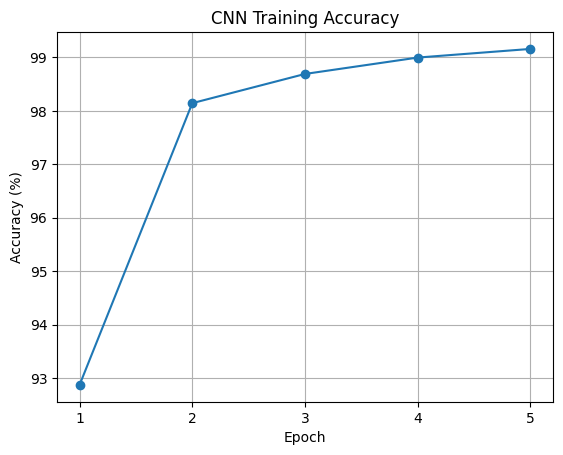

In [12]:
plt.plot(range(1, epochs + 1), train_accuracies, marker="o")
plt.title("CNN Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.xticks(range(1, epochs + 1))
plt.grid(True)
plt.show()

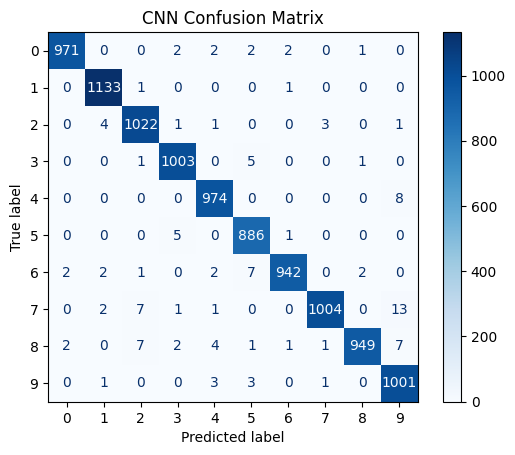

In [13]:
cm = confusion_matrix(all_labels, all_predictions)
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=range(10))
display.plot(cmap="Blues")
plt.title("CNN Confusion Matrix")
plt.show()